In [1]:
import numpy as np

templates = np.load(r'C:\Maze\KilosortData\2008\templates.npy')
amplitudes = np.load(r'C:\Maze\KilosortData\2008\amplitudes.npy')

In [4]:
len(amplitudes)

19647532

In [43]:
import pandas as pd

cluster_info = pd.read_csv(r"C:\Maze\KilosortData\2008\cluster_info.tsv", sep='\t')
cluster_rawAmplitude = pd.read_csv(r"C:\Maze\KilosortData\2008\cluster_rawAmplitude.tsv", sep='\t')

In [3]:
# Create a dictionary of DataFrames, one for each unique bc_unitType
unit_type_dfs = {unit_type: cluster_info[cluster_info['bc_unitType'] == unit_type] for unit_type in cluster_info['bc_unitType'].unique()}

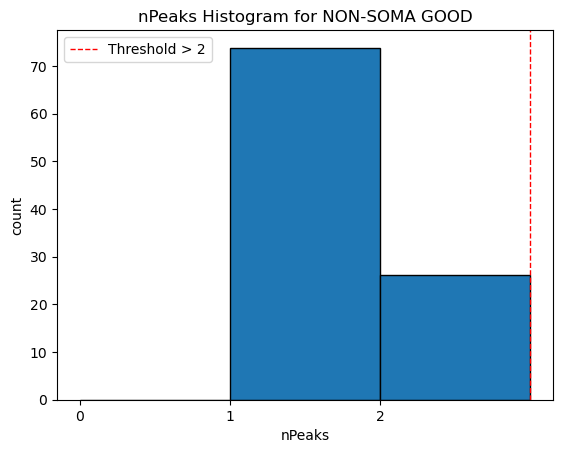

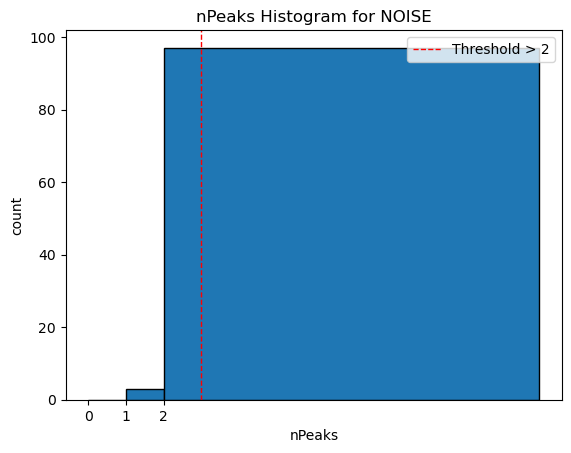

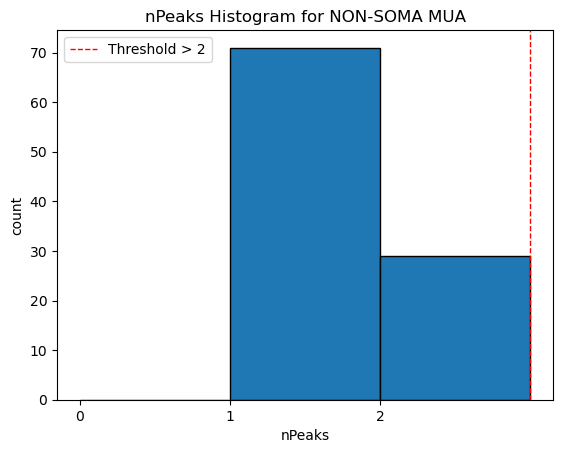

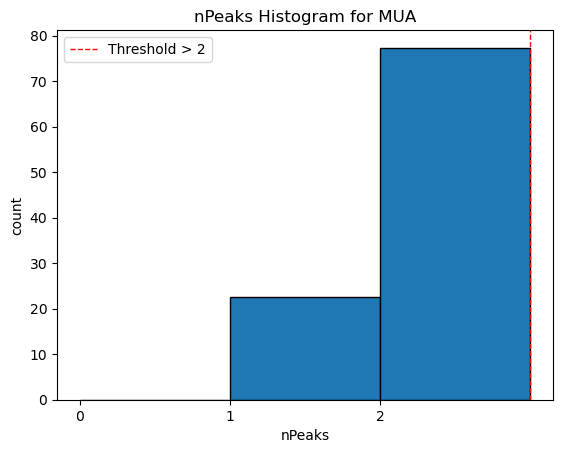

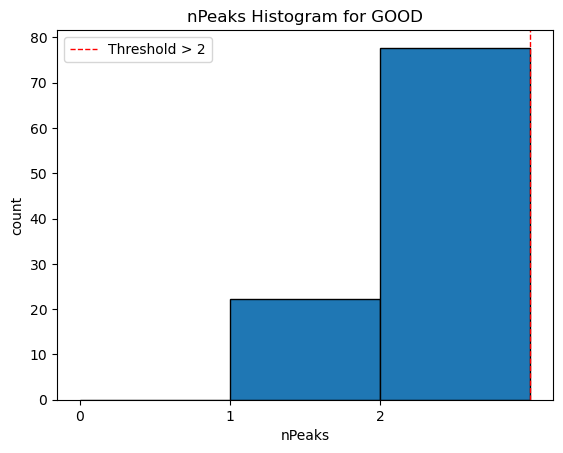

In [4]:
import matplotlib.pyplot as plt

for unit_type, df in unit_type_dfs.items():
    plt.figure()
    n, bins_hist, patches = plt.hist(df['nPeaks'].dropna(), bins=[0, 1, 2, df['nPeaks'].max()+1], edgecolor='black', density=False)
    percentages = n / n.sum() * 100
    plt.clf()  # Clear the current figure to plot percentages
    plt.bar(bins_hist[:-1], percentages, width=np.diff(bins_hist), align='edge', edgecolor='black')
    # Draw threshold line just after the bar for nPeaks == 2
    threshold_x = 2 + 1
    plt.axvline(threshold_x, color='red', linestyle='dashed', linewidth=1, label='Threshold > 2')
    plt.title(f'nPeaks Histogram for {unit_type}')
    plt.xlabel('nPeaks')
    plt.ylabel('count')
    plt.xticks([int(x) for x in bins_hist[:-1]])  # Show integer nPeaks values as x-ticks
    plt.legend()
    plt.show()

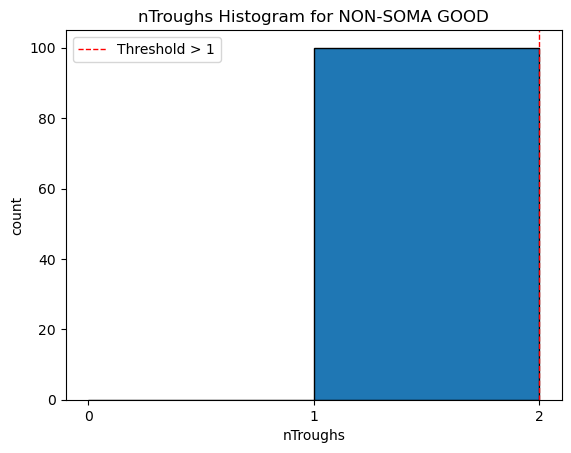

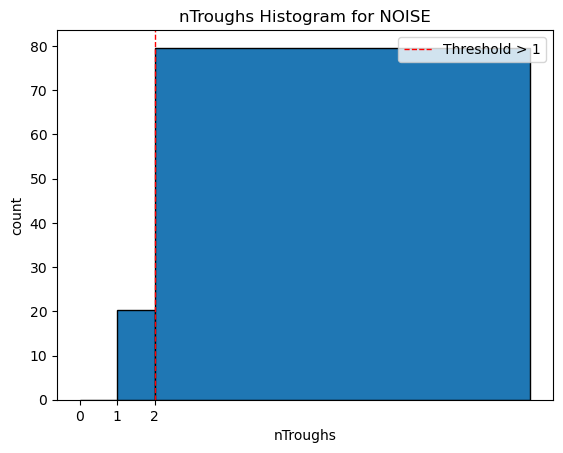

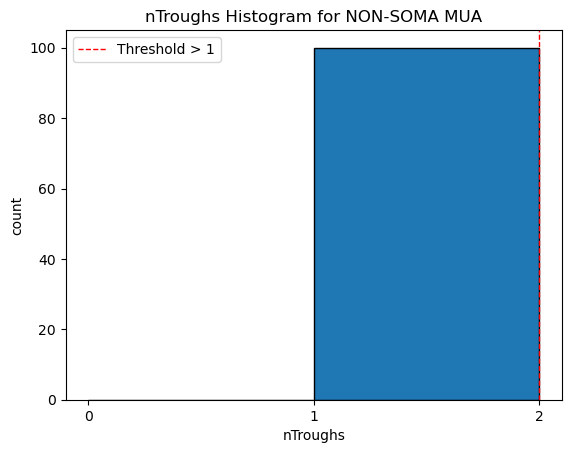

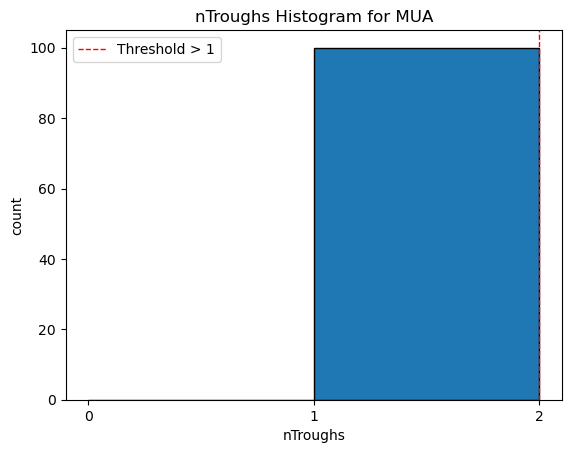

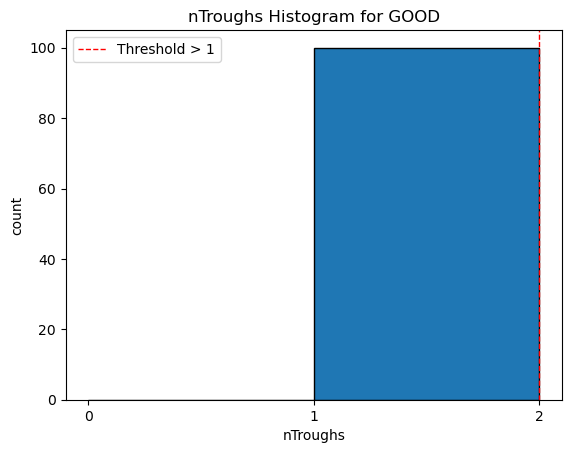

In [5]:
for unit_type, df in unit_type_dfs.items():
    plt.figure()
    n, bins_hist, patches = plt.hist(df['nTroughs'].dropna(), bins=[0, 1, 2, df['nTroughs'].max()+1], edgecolor='black', density=False)
    percentages = n / n.sum() * 100
    plt.clf()  # Clear the current figure to plot percentages
    plt.bar(bins_hist[:-1], percentages, width=np.diff(bins_hist), align='edge', edgecolor='black')
    # Draw threshold line just after the bar for nTroughs == 1
    threshold_x = 1 + 1
    plt.axvline(threshold_x, color='red', linestyle='dashed', linewidth=1, label='Threshold > 1')
    plt.title(f'nTroughs Histogram for {unit_type}')
    plt.xlabel('nTroughs')
    plt.ylabel('count')
    plt.xticks([int(x) for x in bins_hist[:-1]])  # Show integer nTroughs values as x-ticks
    plt.legend()
    plt.show()

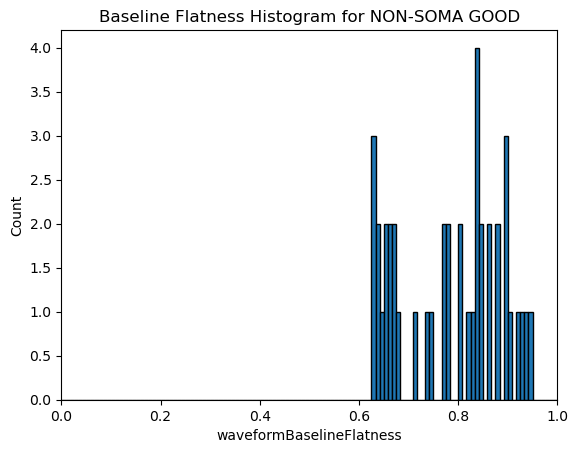

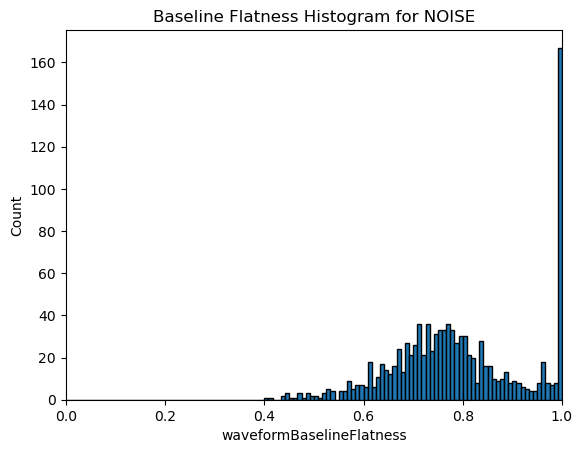

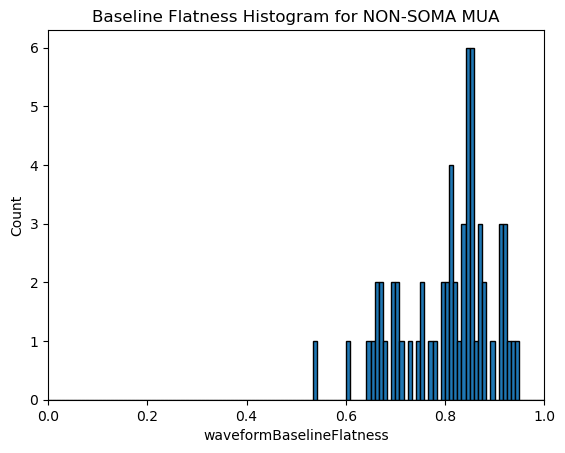

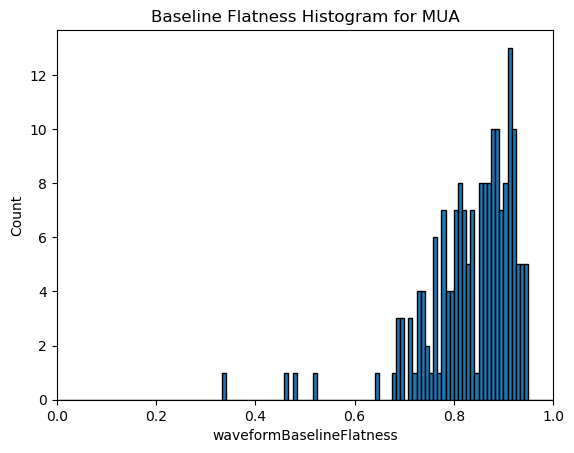

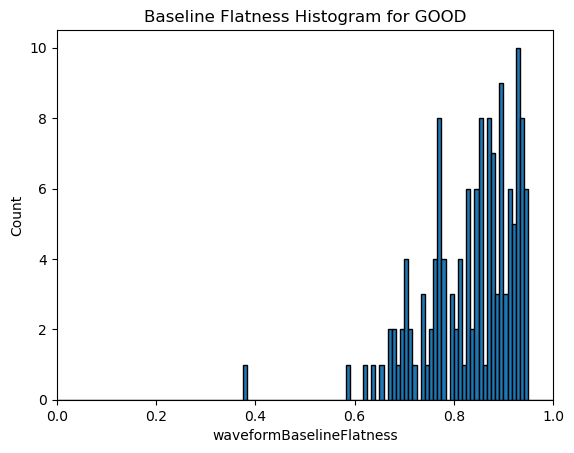

In [6]:
# Draw histograms for waveformBaselineFlatness for each unit type
num_bins = 120  # You can adjust the number of bins as needed
for unit_type, df in unit_type_dfs.items():
    plt.figure()
    data = df['waveformBaselineFlatness'].dropna()
    plt.hist(data, bins=np.linspace(0, 1, num_bins + 1), edgecolor='black', density=False)
    plt.title(f'Baseline Flatness Histogram for {unit_type}')
    plt.xlabel('waveformBaselineFlatness')
    plt.ylabel('Count')
    plt.xlim(0, 1)
    plt.show()

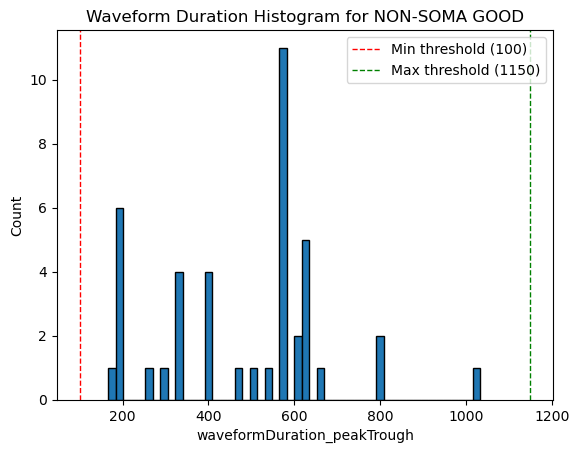

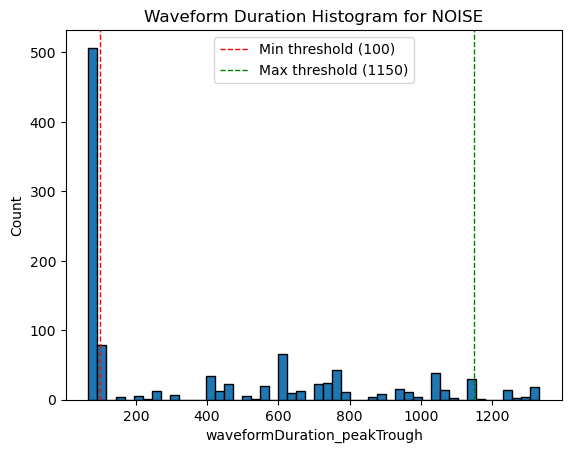

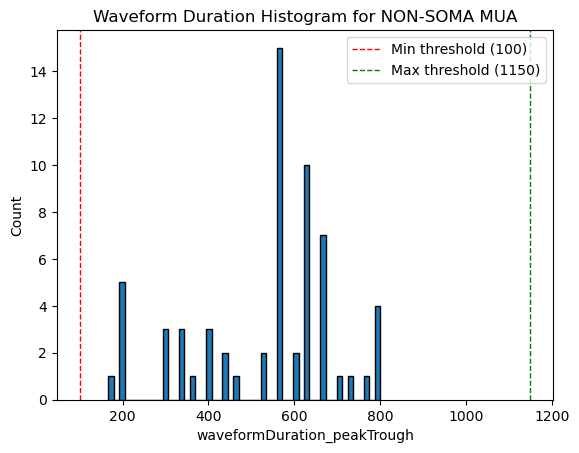

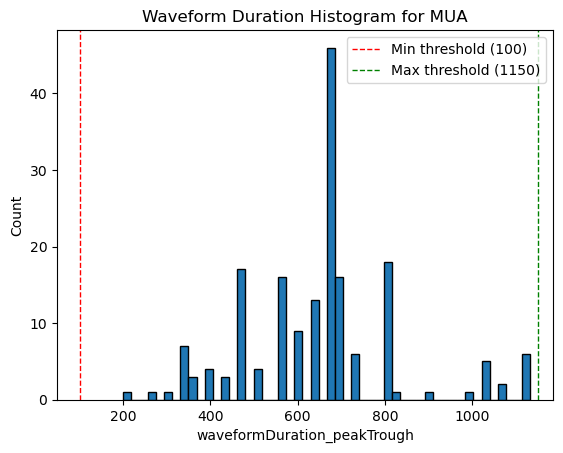

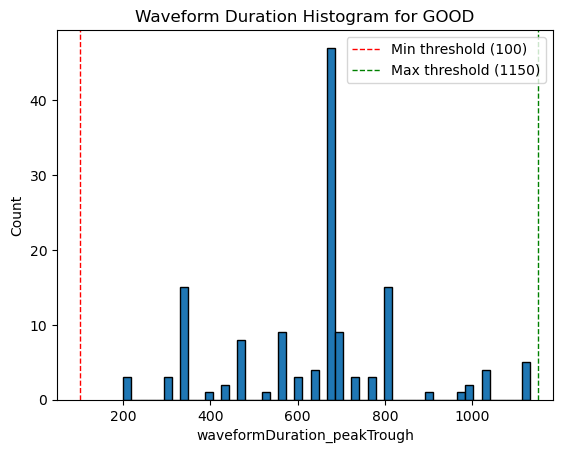

In [7]:
# Draw histograms for waveformDuration_peakTrough for each unit type with threshold lines
for unit_type, df in unit_type_dfs.items():
    plt.figure()
    data = df['waveformDuration_peakTrough'].dropna()
    plt.hist(data, bins=50, edgecolor='black', density=False)
    plt.axvline(100, color='red', linestyle='dashed', linewidth=1, label='Min threshold (100)')
    plt.axvline(1150, color='green', linestyle='dashed', linewidth=1, label='Max threshold (1150)')
    plt.title(f'Waveform Duration Histogram for {unit_type}')
    plt.xlabel('waveformDuration_peakTrough')
    plt.ylabel('Count')
    plt.legend()
    plt.show()

In [8]:
%pip install bombcell

Note: you may need to restart the kernel to use updated packages.


In [9]:
import os, sys
from pathlib import Path
from pprint import pprint 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bombcell as bc

✅ ipywidgets available - interactive GUI ready


In [63]:
ks_dir = r"C:\Maze\KilosortData\2907"

param = bc.get_default_parameters(ks_dir, 
                                  raw_file=None,
                                  meta_file=None,
                                  kilosort_version=2)

In [65]:
param["saveAsTSV"] = 1
param["maxWvBaselineFraction"] = 1
param["probeType"] = 2
param["minNumSpikes"] = 50
param["hillOrLlobetMethod"] = True # Work very slowly for False (Llobe method) that should be more accurate
param["computeTimeChunks"] = True

In [25]:
param_to_col["maxNPeaks"]

'nPeaks'

In [61]:
param_thresholds

{'maxNPeaks': 2,
 'maxNTroughs': 1,
 'maxWvBaselineFraction': 1,
 'WvDuration': (100, 1150),
 'maxScndPeakToTroughRatio_noise': 0.8,
 'minSpatialDecaySlope': -0.008,
 'maxPeak1ToPeak2Ratio_nonSomatic': 3,
 'maxMainPeakToTroughRatio_nonSomatic': 0.8,
 'maxRPVviolations': 0.1,
 'minNumSpikes': 50,
 'minPresenceRatio': 0.7,
 'maxPercSpikesMissing': 20}

In [66]:
# Define the list of parameters to plot (combine min/max duration as one entry)
param_list_combined = [
    "maxNPeaks", "maxNTroughs", "maxWvBaselineFraction", "WvDuration",
    "maxScndPeakToTroughRatio_noise", "minSpatialDecaySlope", "maxPeak1ToPeak2Ratio_nonSomatic", "maxMainPeakToTroughRatio_nonSomatic",
    "maxRPVviolations", "minNumSpikes", "minPresenceRatio", "maxPercSpikesMissing"
]

# Map parameter names to DataFrame column names
param_to_col = {
    "maxNPeaks": "nPeaks",
    "maxNTroughs": "nTroughs",
    "maxWvBaselineFraction": "waveformBaselineFlatness",
    "WvDuration": "waveformDuration_peakTrough",
    "maxScndPeakToTroughRatio_noise": "scndPeakToTroughRatio",
    "minSpatialDecaySlope": "spatialDecaySlope",
    "maxPeak1ToPeak2Ratio_nonSomatic": "peak1ToPeak2Ratio",
    "maxMainPeakToTroughRatio_nonSomatic": "mainPeakToTroughRatio",
    "maxRPVviolations": "fractionRPVs_estimatedTauR",
    "minNumSpikes": "n_spikes",
    "minPresenceRatio": "presenceRatio",
    "maxPercSpikesMissing": "percentageSpikesMissing_gaussian"
}

# Set thresholds for each parameter
param_thresholds = {
    "maxNPeaks": param["maxNPeaks"] if "maxNPeaks" in param else 2,
    "maxNTroughs": param["maxNTroughs"] if "maxNTroughs" in param else 1,
    "maxWvBaselineFraction": param["maxWvBaselineFraction"],
    "WvDuration": (param["minWvDuration"], param["maxWvDuration"]),
    "maxScndPeakToTroughRatio_noise": param["maxScndPeakToTroughRatio_noise"],
    "minSpatialDecaySlope": param["minSpatialDecaySlope"],
    "maxPeak1ToPeak2Ratio_nonSomatic": param["maxPeak1ToPeak2Ratio_nonSomatic"],
    "maxMainPeakToTroughRatio_nonSomatic": param["maxMainPeakToTroughRatio_nonSomatic"],
    "maxRPVviolations": param["maxRPVviolations"],
    "minNumSpikes": param["minNumSpikes"],
    "minPresenceRatio": param["minPresenceRatio"],
    "maxPercSpikesMissing": param["maxPercSpikesMissing"]
}

ncols = 4
nrows = 3
total_plots = ncols * nrows

for param_name in param_list_combined:
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5, nrows*3))
    axes = axes.flatten()
    # Get threshold string for title
    if param_name == "WvDuration":
        min_thresh, max_thresh = param_thresholds["WvDuration"]
        thresh_str = f"[{min_thresh}, {max_thresh}]"
    else:
        thresh_str = f"{param_thresholds[param_name]}"
    for idx, other_param in enumerate(param_list_combined):
        if other_param == param_name:
            axes[idx].axis('off')
            continue
        col = param_to_col[other_param]
        col_filter = param_to_col[param_name]
        # Filter cluster_info by the threshold for the current param_name
        if param_name == "WvDuration":
            min_thresh, max_thresh = param_thresholds["WvDuration"]
            filtered = cluster_info[
                (cluster_info[col_filter] >= min_thresh) &
                (cluster_info[col_filter] <= max_thresh)
            ]
        elif "min" in param_name:
            thresh = param_thresholds[param_name]
            filtered = cluster_info[cluster_info[col_filter] >= thresh]
        else:
            thresh = param_thresholds[param_name]
            filtered = cluster_info[cluster_info[col_filter] <= thresh]

        data = filtered[col].dropna()
        axes[idx].hist(data, bins=50, edgecolor='black')
        if other_param == "WvDuration":
            min_t, max_t = param_thresholds["WvDuration"]
            axes[idx].axvline(min_t, color='red', linestyle='dashed', label=f"min={min_t}")
            axes[idx].axvline(max_t, color='green', linestyle='dashed', label=f"max={max_t}")
        else:
            thresh = param_thresholds[other_param]
            if "min" in other_param:
                axes[idx].axvline(thresh, color='red', linestyle='dashed', label=f"min={thresh}")
            elif "max" in other_param:
                axes[idx].axvline(thresh, color='green', linestyle='dashed', label=f"max={thresh}")
        axes[idx].set_title(f"{col}")
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel("Count")
        axes[idx].legend()
    n_clusters = len(filtered)
    fig.suptitle(
        f"Histograms of parameters (filtered by {param_name}, threshold={thresh_str}, n_clusters={n_clusters})",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(rf"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\FilteredHistograms\histograms_filtered_by_{param_name}.png")
    plt.close()


In [67]:
for param in params_to_plot:
    fig, axes = plt.subplots(1, n_types, figsize=(5 * n_types, 4), sharey=True)
    if n_types == 1:
        axes = [axes]
    for i, unit_type in enumerate(unit_types):
        data = unit_type_dfs[unit_type][param].dropna()
        n, bins_hist, patches = axes[i].hist(data, bins=50, edgecolor='black', density=False)
        percentages = n / n.sum() * 100 
        axes[i].cla()
        axes[i].bar(bins_hist[:-1], percentages, width=np.diff(bins_hist), align='edge', edgecolor='black')
        # Add threshold lines if available
        for key, colname in param_to_col.items():
            if colname == param:
                if key == "WvDuration":
                    min_t, max_t = param_thresholds["WvDuration"]
                    axes[i].axvline(min_t, color='red', linestyle='dashed', linewidth=1, label=f"min={min_t}")
                    axes[i].axvline(max_t, color='green', linestyle='dashed', linewidth=1, label=f"max={max_t}")
                else:
                    thresh = param_thresholds.get(key, None)
                    if thresh is not None:
                        if "min" in key:
                            axes[i].axvline(thresh, color='red', linestyle='dashed', linewidth=1, label=f"min={thresh}")
                        elif "max" in key:
                            axes[i].axvline(thresh, color='green', linestyle='dashed', linewidth=1, label=f"max={thresh}")
        axes[i].set_title(f"{unit_type}")
        axes[i].set_xlabel(param)
        axes[i].set_ylabel("Percentage")
        axes[i].set_ylim(0, 100)
        axes[i].legend()
    fig.suptitle(f"Distribution of {param} by bc_unitType", fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(fr"G:\Shared drives\FinkelsteinLab\People\AlmogMeir\NPC1\2008\DisributionByTypes\distribution_{param}.png")
    plt.close()
